In [1]:
from pynwb import NWBHDF5IO
import pandas as pd

FILES = {
    "688277": "../../data/raw/688277-20230921-v001.nwb",
    "692644": "../../data/raw/692644-20230907-v001.nwb",
}
PROBES = ["probeB", "probeD", "probeF"]

# Open one file (this doesn't load the big data yet)
io = NWBHDF5IO(FILES["688277"], "r")
nwbfile = io.read()

# What recordings are in this file? (checking for EEG)
print("Acquisition contents:", list(nwbfile.acquisition.keys()))

# Probe B's LFP and its "seating chart"
lfp = nwbfile.acquisition["LFP"]["ElectricalSeriesprobeB"]
elec = lfp.electrodes.to_dataframe()   # one row per LFP channel, in data order

print("Number of channels:", len(elec))
print("Columns:", elec.columns.tolist())
print("Data shape / type / rate:", lfp.data.shape, lfp.data.dtype, lfp.rate)
elec.head()

Acquisition contents: ['ElectricalSeriesEEG', 'LFP', 'isoflurane_level']
Number of channels: 384
Columns: ['location', 'group', 'is_data_valid', 'probe_vertical_position', 'probe_horizontal_position', 'group_name', 'x', 'y', 'z', 'reference']
Data shape / type / rate: (11534078, 384) int16 None


,location,group,is_data_valid,probe_vertical_position,probe_horizontal_position,group_name,x,y,z,reference
id,,,,,,,,,,
30,VAL,probeB pynwb.ecephys.ElectrodeGroup at 0x46735...,True,20,43,probeB,242.0,175.0,183.0,"stainless steel skull screw, left CB"
31,VAL,probeB pynwb.ecephys.ElectrodeGroup at 0x46735...,True,20,11,probeB,242.0,174.0,183.0,"stainless steel skull screw, left CB"
32,VAL,probeB pynwb.ecephys.ElectrodeGroup at 0x46735...,True,40,59,probeB,242.0,174.0,183.0,"stainless steel skull screw, left CB"
33,AV,probeB pynwb.ecephys.ElectrodeGroup at 0x46735...,True,40,27,probeB,243.0,174.0,183.0,"stainless steel skull screw, left CB"
34,AV,probeB pynwb.ecephys.ElectrodeGroup at 0x46735...,True,60,43,probeB,243.0,174.0,183.0,"stainless steel skull screw, left CB"


In [2]:
# 1. Sampling rate, from the timestamps
ts = lfp.timestamps
print("First timestamps:", ts[:3])
print("Last timestamp (s):", ts[-1], "→ minutes:", ts[-1] / 60)
print("Estimated rate (Hz):", 1 / (ts[1] - ts[0]))

# 2. Conversion factor from int16 to volts
print("Conversion factor:", lfp.conversion)

# 3. How many channels are flagged invalid?
print(elec["is_data_valid"].value_counts())

# 4. Which regions does probe B pass through, and how many channels each?
print(elec["location"].value_counts())

First timestamps: [18.66490541 18.6653054  18.6657054 ]
Last timestamp (s): 4632.285202127705 → minutes: 77.20475336879508
Estimated rate (Hz): 2500.0045749324204
Conversion factor: 1.9499999999999999e-07
is_data_valid
True     370
False     14
Name: count, dtype: int64
location
AV           85
CA3          54
LD           34
fi           32
SSp-tr6a     26
RSPagl2/3    26
SSp-tr5      25
SSp-ll6a     14
CA2          13
null         13
ccb          11
RSPagl5      11
RSPagl1      11
alv          10
cing         10
VAL           3
root          3
SSp-ll6b      2
CA1           1
Name: count, dtype: int64


In [3]:
def region_ranges(elec_df):
    """Group consecutive channels with the same region label into ranges."""
    locs = elec_df["location"].astype(str).to_numpy()
    valid = elec_df["is_data_valid"].astype(bool).to_numpy()
    rows = []
    start = 0
    for ch in range(1, len(locs) + 1):
        # A range ends when the label changes (or we reach the last channel)
        if ch == len(locs) or locs[ch] != locs[start]:
            rows.append({
                "region": locs[start],
                "ch_start": start,
                "ch_end": ch - 1,
                "n_channels": ch - start,
                "n_invalid": int((~valid[start:ch]).sum()),
            })
            start = ch
    return pd.DataFrame(rows)


all_maps = []
for session, path in FILES.items():
    with NWBHDF5IO(path, "r") as io_s:
        nwb_s = io_s.read()
        for probe in PROBES:
            e = nwb_s.acquisition["LFP"][f"ElectricalSeries{probe}"].electrodes.to_dataframe()
            m = region_ranges(e)
            m.insert(0, "probe", probe)
            m.insert(0, "session", session)
            all_maps.append(m)

region_map = pd.concat(all_maps, ignore_index=True)

# Show probe B of the isoflurane file first
region_map[(region_map["session"] == "688277") & (region_map["probe"] == "probeB")]

,session,probe,region,ch_start,ch_end,n_channels,n_invalid
0,688277,probeB,VAL,0,2,3,0
1,688277,probeB,AV,3,87,85,0
2,688277,probeB,LD,88,121,34,0
3,688277,probeB,root,122,124,3,0
4,688277,probeB,fi,125,156,32,0
5,688277,probeB,alv,157,161,5,0
6,688277,probeB,CA3,162,215,54,1
7,688277,probeB,CA2,216,228,13,0
8,688277,probeB,CA1,229,229,1,0
9,688277,probeB,alv,230,234,5,0


In [4]:
for (session, probe), m in region_map.groupby(["session", "probe"]):
    print(f"\n=== {session} {probe} ===")
    print(m[["region", "ch_start", "ch_end", "n_channels", "n_invalid"]].to_string(index=False))


=== 688277 probeB ===
   region  ch_start  ch_end  n_channels  n_invalid
      VAL         0       2           3          0
       AV         3      87          85          0
       LD        88     121          34          0
     root       122     124           3          0
       fi       125     156          32          0
      alv       157     161           5          0
      CA3       162     215          54          1
      CA2       216     228          13          0
      CA1       229     229           1          0
      alv       230     234           5          0
      ccb       235     245          11          0
     cing       246     255          10          0
 SSp-ll6b       256     257           2          0
 SSp-ll6a       258     271          14          0
 SSp-tr6a       272     297          26          0
  SSp-tr5       298     322          25          0
  RSPagl5       323     333          11          0
RSPagl2/3       334     359          26          0
  RSPagl

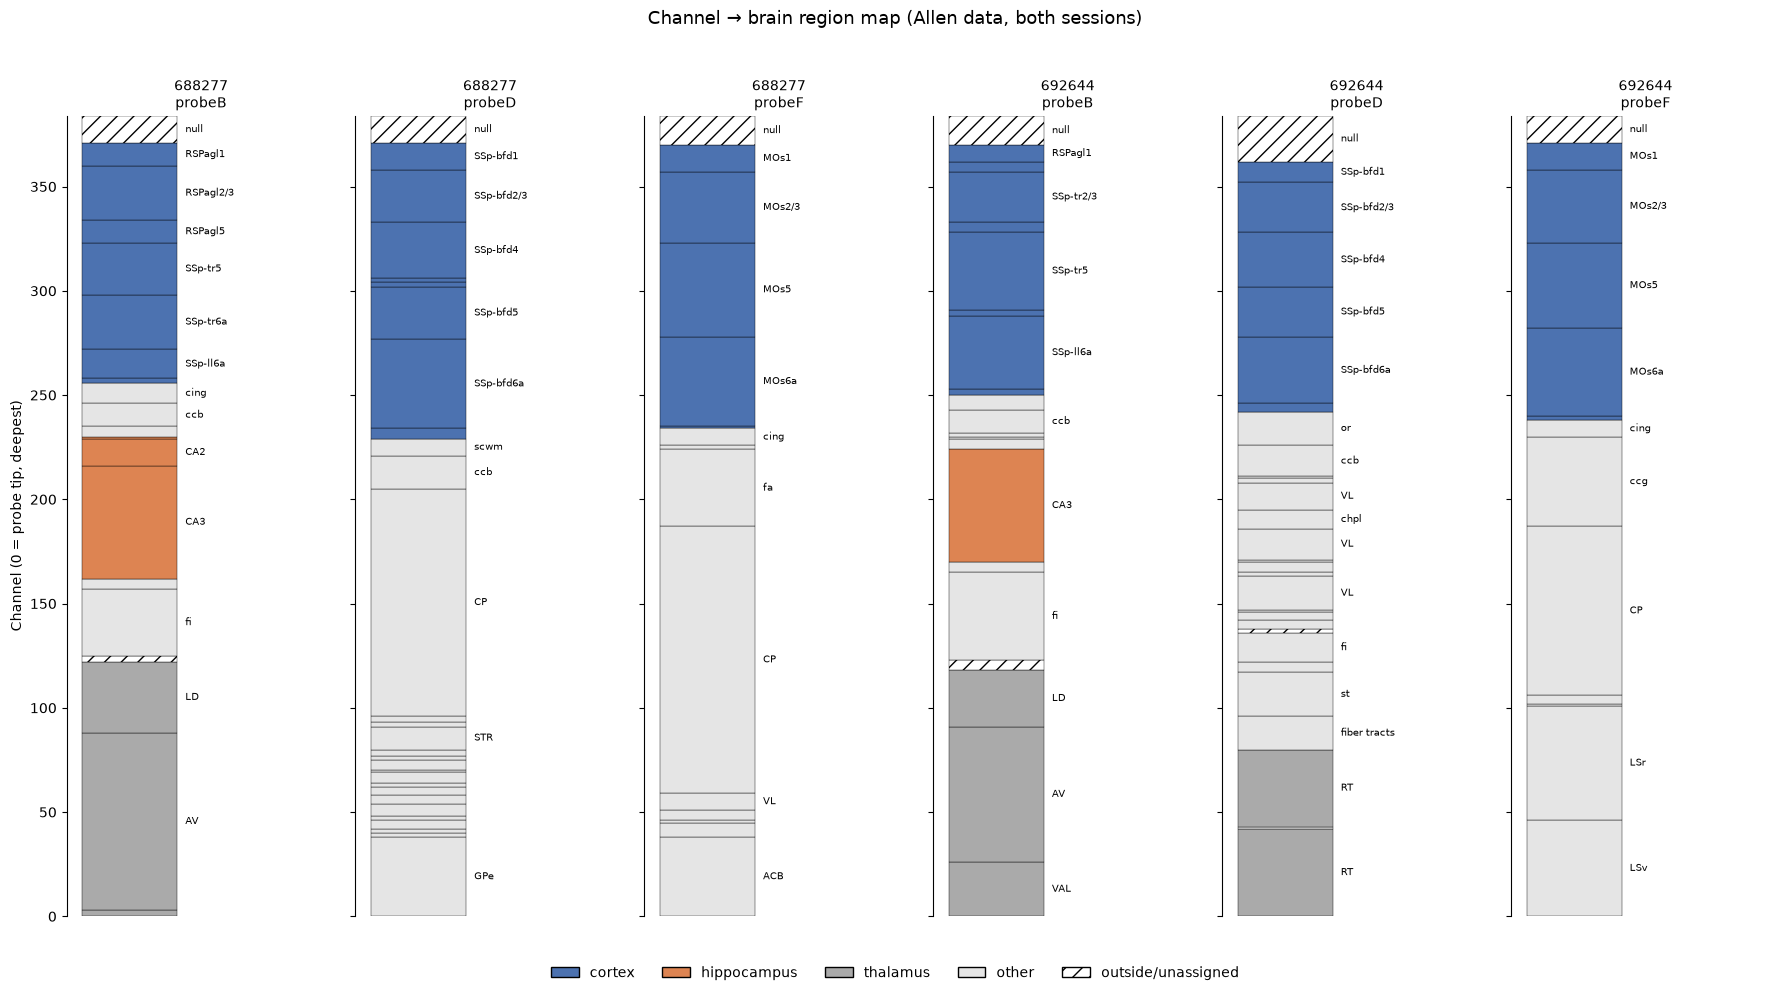

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def region_category(label):
    """Sort Allen region labels into the groups we care about."""
    if label.startswith(("SSp", "MOs", "RSP")):
        return "cortex"
    if label in ("CA1", "CA2", "CA3", "DG"):
        return "hippocampus"
    if label in ("VAL", "AV", "LD", "RT"):
        return "thalamus"
    if label in ("null", "root"):
        return "outside/unassigned"
    return "other"   # striatum, septum, ventricle, fiber tracts, etc.

region_map["category"] = region_map["region"].apply(region_category)

CATEGORY_COLORS = {
    "cortex": "#4C72B0",              # blue
    "hippocampus": "#DD8452",         # orange
    "thalamus": "#AAAAAA",            # dark gray
    "other": "#E5E5E5",               # light gray
    "outside/unassigned": "white",    # hatched
}

groups = list(region_map.groupby(["session", "probe"]))
fig, axes = plt.subplots(1, len(groups), figsize=(18, 10), sharey=True)

for ax, ((session, probe), m) in zip(axes, groups):
    for _, row in m.iterrows():
        # One colored block per region range
        ax.bar(0, row["n_channels"], bottom=row["ch_start"], width=0.6,
               color=CATEGORY_COLORS[row["category"]],
               edgecolor="black", linewidth=0.3,
               hatch="//" if row["category"] == "outside/unassigned" else None)
        # Write the region name next to blocks big enough to read
        if row["n_channels"] >= 8:
            ax.text(0.35, row["ch_start"] + row["n_channels"] / 2, row["region"],
                    va="center", fontsize=7)
    ax.set_title(f"{session}\n{probe}", fontsize=10)
    ax.set_xlim(-0.4, 1.3)
    ax.set_xticks([])
    for side in ["top", "right", "bottom"]:
        ax.spines[side].set_visible(False)

axes[0].set_ylim(0, 384)
axes[0].set_ylabel("Channel (0 = probe tip, deepest)")

legend_items = [Patch(facecolor=c, edgecolor="black",
                      hatch="//" if k == "outside/unassigned" else None, label=k)
                for k, c in CATEGORY_COLORS.items()]
fig.legend(handles=legend_items, loc="lower center", ncol=5, frameon=False)
fig.suptitle("Channel → brain region map (Allen data, both sessions)", fontsize=13)
plt.tight_layout(rect=[0, 0.05, 1, 0.96])

# Uncomment to save an image you can post in Slack:
# fig.savefig("channel_region_map.png", dpi=200, bbox_inches="tight")
plt.show()